# PathSnap - 03 Model experimentation and comparison

**Task for the classifier:** for each (GPS point, candidate arc) row predict P(candidate is the true arc). Binary, ~17% positives.

**Data / partitions**
* Fit + cross-validation: the 80 `train` trips, **GroupKFold(5) by trip** (no trip is in both the fit and validation folds).
* Development comparison: the 10 `student_test` trips (never used for fitting).
* Rows from unlabelled points (label = -1, unreliable reference) are not used for fitting or scoring.

**Metrics** (src/metrics.py): accuracy, precision, recall, F1, **macro F1**, log loss, confusion matrix at threshold 0.5 on candidate rows;
**point-level Top-1 accuracy** (best-scored candidate = true arc; points without candidates count as wrong);
**route continuity** (consecutive predicted arcs equal or connected); training and inference time.

**Primary selection metric: cross-validated point-level Top-1 accuracy.** It is exactly the map-matching objective
(one arc per GPS point) and it is what the HMM improves on. Log loss is the secondary check because the HMM uses the probabilities as emissions.

In [1]:
import sys, time, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import GroupKFold
from sklearn.metrics import log_loss, f1_score

sys.path.insert(0, str(Path.cwd().parent / "src"))
from features import FEATURES
from metrics import evaluate, load_arcs
from models import make_models, SEED

FEAT = Path.cwd().parent / "outputs" / "features"
OUT = Path.cwd().parent / "outputs" / "models"; (OUT / "plots").mkdir(parents=True, exist_ok=True)
ctr = pd.read_parquet(FEAT / "candidates_train.parquet"); ptr = pd.read_parquet(FEAT / "points_train.parquet")
cte = pd.read_parquet(FEAT / "candidates_student_test.parquet"); pte = pd.read_parquet(FEAT / "points_student_test.parquet")
arcs = {**load_arcs("train"), **load_arcs("student_test")}
rng = np.random.default_rng(SEED)
print(len(ctr), "train rows,", ctr.trip_id.nunique(), "trips |", len(cte), "student_test rows")

1085223 train rows, 80 trips | 113694 student_test rows


## 1. Models and initial configurations

In [2]:
models = make_models()
cfg = pd.DataFrame([{"model": n, "family": f, "max_fit_rows": cap, "config": str(e)} for n, (f, e, cap) in models.items()])
cfg.to_csv(OUT / "model_configs.csv", index=False); cfg

,model,family,max_fit_rows,config
0,LogisticRegression,Linear,NaN,"Pipeline(steps=[('standardscaler', StandardSca..."
1,GaussianNB,Probabilistic,NaN,GaussianNB()
2,KNN,Instance-based,60000.0,"Pipeline(steps=[('standardscaler', StandardSca..."
3,RandomForest,Ensemble (bagging),NaN,"RandomForestClassifier(max_depth=18, max_sampl..."
4,LightGBM,Boosting,NaN,"LGBMClassifier(learning_rate=0.05, n_estimator..."
5,MLP,Neural network,300000.0,"Pipeline(steps=[('standardscaler', StandardSca..."


## 2. Group-aware 5-fold cross-validation on the 80 train trips

In [3]:
def fit_rows(c, cap):
    lab = c[c.label >= 0]
    return lab if cap is None or len(lab) <= cap else lab.sample(cap, random_state=SEED)

gkf = GroupKFold(n_splits=5)
trips = ctr.trip_id.unique()
fold_rows = []
t_all = time.time()
for name, (fam, est, cap) in models.items():
    for k, (tr_i, va_i) in enumerate(gkf.split(trips, groups=trips)):
        tr_t, va_t = set(trips[tr_i]), set(trips[va_i])
        c_tr, c_va = ctr[ctr.trip_id.isin(tr_t)], ctr[ctr.trip_id.isin(va_t)]
        fr = fit_rows(c_tr, cap)
        m = clone(est); t0 = time.time(); m.fit(fr[FEATURES], fr.label); t_fit = time.time() - t0
        prob = m.predict_proba(c_va[FEATURES])[:, 1]
        r = evaluate(c_va, prob, ptr[ptr.trip_id.isin(va_t)], arcs)
        ev = fr.sample(min(100_000, len(fr)), random_state=SEED)   # random sample of the fitted rows
        r.update(model=name, fold=k, fit_time_s=t_fit, train_macro_f1=f1_score(ev.label, m.predict_proba(ev[FEATURES])[:, 1] >= .5, average="macro"))
        fold_rows.append(r)
    print(f"{name:20s} done ({time.time()-t_all:.0f}s elapsed)")
cv = pd.DataFrame(fold_rows); cv.drop(columns="confusion_matrix").to_csv(OUT / "cv_folds.csv", index=False)
cv_sum = cv.groupby("model", sort=False)[["macro_f1", "top1_acc", "log_loss", "route_continuity", "train_macro_f1", "fit_time_s"]].agg(["mean", "std"]).round(4)
cv_sum

LogisticRegression   done (5s elapsed)


GaussianNB           done (6s elapsed)


KNN                  done (36s elapsed)


RandomForest         done (153s elapsed)


LightGBM             done (182s elapsed)


MLP                  done (201s elapsed)


/Users/praneel/Desktop/mlhackathon/pathsnap/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (25) reached and the optimization hasn't converged yet.
  warnings.warn(


macro_f1         top1_acc         log_loss          \
                       mean     std     mean     std     mean     std   
model                                                                   
LogisticRegression   0.8880  0.0332   0.8457  0.0587   0.1745  0.0408   
GaussianNB           0.7621  0.0205   0.7704  0.0546   1.2551  0.2450   
KNN                  0.8951  0.0356   0.8387  0.0583   0.1910  0.0655   
RandomForest         0.9137  0.0361   0.8596  0.0597   0.1205  0.0410   
LightGBM             0.9145  0.0352   0.8615  0.0602   0.1183  0.0434   
MLP                  0.9079  0.0356   0.8553  0.0599   0.1286  0.0439   

                   route_continuity         train_macro_f1         fit_time_s  \
                               mean     std           mean     std       mean   
model                                                                           
LogisticRegression           0.9304  0.0090         0.8865  0.0094     0.8236   
GaussianNB                   0.9199  0.0150         0.7609  0.0091     0.0729   
KNN                          0.9400  0.0078         1.0000  0.0000     0.0068   
RandomForest                 0.9458  0.0044         0.9245  0.0085    22.6336   
LightGBM                     0.9483  0.0047         0.9339  0.0073     4.6918   
MLP                          0.9488  0.0049         0.9119  0.0088     3.7293   

                            
                       std  
model                       
LogisticRegression  0.0926  
GaussianNB          0.0028  
KNN                 0.0005  
RandomForest        1.8066  
LightGBM            0.2066  
MLP                 0.6301

## 3. Refit on all 80 train trips, evaluate on the 10 student_test trips

In [4]:
test_rows, test_probs, fitted = [], {}, {}
for name, (fam, est, cap) in models.items():
    fr = fit_rows(ctr, cap)
    m = clone(est); t0 = time.time(); m.fit(fr[FEATURES], fr.label); t_fit = time.time() - t0
    t0 = time.time(); prob = m.predict_proba(cte[FEATURES])[:, 1]; t_inf = time.time() - t0
    r = evaluate(cte, prob, pte, arcs)
    r.update(model=name, family=fam, fit_time_s=t_fit, inference_s=t_inf, inference_ms_per_1k_points=1000 * t_inf / len(pte) * 1000)
    test_rows.append(r); test_probs[name] = prob; fitted[name] = m
    print(f"{name:20s} top1={r['top1_acc']:.4f} macroF1={r['macro_f1']:.4f} logloss={r['log_loss']:.4f}")

# non-ML reference: always choose the nearest candidate
base_prob = (cte.dist_rank == 0).astype(float).values
b = evaluate(cte, np.clip(base_prob, .02, .98), pte, arcs); b.update(model="Baseline: nearest arc", family="Rule (not ML)")
test = pd.DataFrame(test_rows + [b])
pd.DataFrame(test_probs).assign(trip_id=cte.trip_id.values, point_idx=cte.point_idx.values, arc_id=cte.arc_id.values) \
  .to_parquet(OUT / "student_test_probs.parquet", index=False)

LogisticRegression   top1=0.8482 macroF1=0.8935 logloss=0.1631
GaussianNB           top1=0.7654 macroF1=0.7601 logloss=1.2516


KNN                  top1=0.8467 macroF1=0.9029 logloss=0.1671


RandomForest         top1=0.8705 macroF1=0.9203 logloss=0.1079


LightGBM             top1=0.8770 macroF1=0.9238 logloss=0.1039


MLP                  top1=0.8632 macroF1=0.9127 logloss=0.1168


## 4. Consolidated comparison table (report section 3.1)

In [5]:
cvm = cv.groupby("model")[["macro_f1", "top1_acc", "log_loss", "route_continuity"]].mean().add_prefix("cv_")
cvs = cv.groupby("model")[["macro_f1", "top1_acc"]].std().add_prefix("cv_std_")
table = test.set_index("model").join(cvm).join(cvs).join(cfg.set_index("model")[["max_fit_rows"]])
cols = ["family", "max_fit_rows", "cv_macro_f1", "cv_std_macro_f1", "cv_top1_acc", "cv_std_top1_acc", "cv_log_loss", "cv_route_continuity",
        "accuracy", "precision", "recall", "f1", "macro_f1", "log_loss", "top1_acc", "route_continuity", "fit_time_s", "inference_ms_per_1k_points"]
table = table[cols].rename(columns={c: "test_" + c for c in ["accuracy", "precision", "recall", "f1", "macro_f1", "log_loss", "top1_acc", "route_continuity"]})
table.to_csv(OUT / "model_comparison.csv")
table.round(4)

,family,max_fit_rows,cv_macro_f1,cv_std_macro_f1,cv_top1_acc,cv_std_top1_acc,cv_log_loss,cv_route_continuity,test_accuracy,test_precision,test_recall,test_f1,test_macro_f1,test_log_loss,test_top1_acc,test_route_continuity,fit_time_s,inference_ms_per_1k_points
model,,,,,,,,,,,,,,,,,,
LogisticRegression,Linear,NaN,0.8880,0.0332,0.8457,0.0587,0.1745,0.9304,0.9407,0.8274,0.8176,0.8225,0.8935,0.1631,0.8482,0.9299,1.0091,0.3212
GaussianNB,Probabilistic,NaN,0.7621,0.0205,0.7704,0.0546,1.2551,0.9199,0.8226,0.4853,0.9289,0.6375,0.7601,1.2516,0.7654,0.9242,0.1155,0.3962
KNN,Instance-based,60000.0,0.8951,0.0356,0.8387,0.0583,0.1910,0.9400,0.9468,0.8587,0.8174,0.8376,0.9029,0.1671,0.8467,0.9366,0.0058,118.7613
RandomForest,Ensemble (bagging),NaN,0.9137,0.0361,0.8596,0.0597,0.1205,0.9458,0.9563,0.8879,0.8465,0.8667,0.9203,0.1079,0.8705,0.9443,30.0251,10.0329
LightGBM,Boosting,NaN,0.9145,0.0352,0.8615,0.0602,0.1183,0.9483,0.9579,0.8849,0.8611,0.8728,0.9238,0.1039,0.8770,0.9463,5.2898,14.9001
MLP,Neural network,300000.0,0.9079,0.0356,0.8553,0.0599,0.1286,0.9488,0.9526,0.8865,0.8233,0.8537,0.9127,0.1168,0.8632,0.9456,3.5078,0.8975
Baseline: nearest arc,Rule (not ML),NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.8421,0.5297,0.5311,0.5304,0.7177,0.6349,0.5297,0.8256,NaN,NaN


## 5. Comparison plots

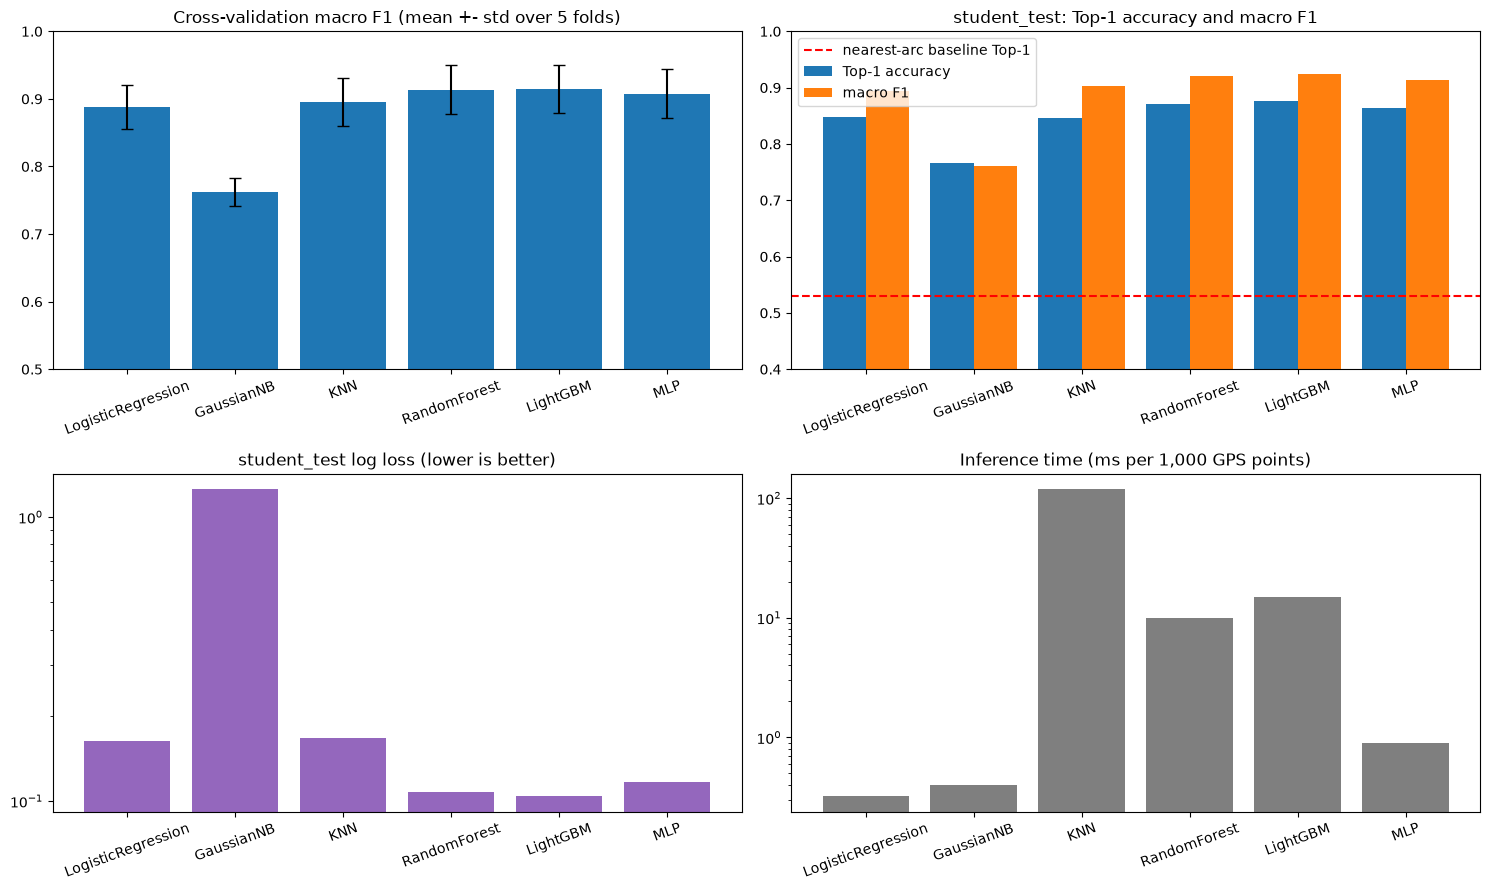

In [6]:
order = [n for n in models]
fig, ax = plt.subplots(2, 2, figsize=(15, 9))
cvg = cv.groupby("model")
ax[0, 0].bar(order, cvg.macro_f1.mean()[order], yerr=cvg.macro_f1.std()[order], capsize=4, color="tab:blue")
ax[0, 0].set(title="Cross-validation macro F1 (mean +- std over 5 folds)", ylim=(0.5, 1))
x = np.arange(len(order)); tt = test.set_index("model")
ax[0, 1].bar(x - .2, tt.top1_acc[order], .4, label="Top-1 accuracy"); ax[0, 1].bar(x + .2, tt.macro_f1[order], .4, label="macro F1")
ax[0, 1].axhline(tt.top1_acc["Baseline: nearest arc"], color="r", ls="--", label="nearest-arc baseline Top-1")
ax[0, 1].set(title="student_test: Top-1 accuracy and macro F1", ylim=(0.4, 1)); ax[0, 1].set_xticks(x, order); ax[0, 1].legend()
ax[1, 0].bar(order, tt.log_loss[order], color="tab:purple"); ax[1, 0].set(title="student_test log loss (lower is better)", yscale="log")
ax[1, 1].bar(order, tt.inference_ms_per_1k_points[order], color="tab:gray"); ax[1, 1].set(title="Inference time (ms per 1,000 GPS points)", yscale="log")
for a in ax.ravel(): a.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig(OUT / "plots/01_model_comparison.png", dpi=130); plt.show()

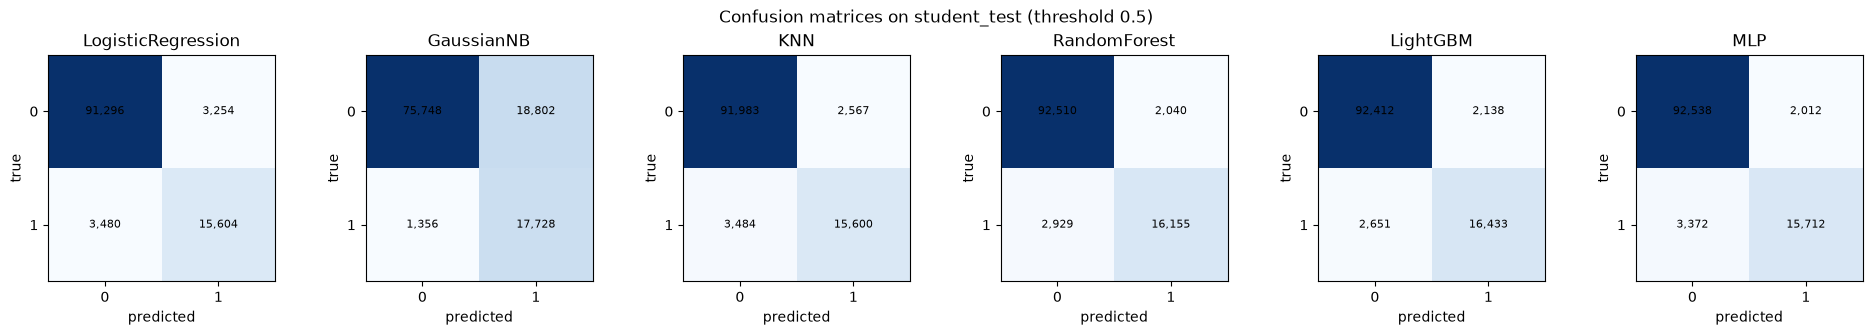

In [7]:
fig, axes = plt.subplots(1, len(order), figsize=(3.2 * len(order), 3.2))
for a, n in zip(axes, order):
    cm = np.array(tt.confusion_matrix[n]); a.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm): a.text(j, i, f"{v:,}", ha="center", va="center", fontsize=8, color="black")
    a.set(title=n, xticks=[0, 1], yticks=[0, 1], xlabel="predicted", ylabel="true")
plt.suptitle("Confusion matrices on student_test (threshold 0.5)"); plt.tight_layout()
plt.savefig(OUT / "plots/02_confusion_matrices.png", dpi=130); plt.show()

## 6. Training histories (only models that actually train epoch by epoch / round by round)
* **MLP**: trained with `partial_fit` one epoch at a time; log loss on the fitted rows and on 16 held-out train trips (GroupShuffleSplit), so the validation curve is genuinely out-of-trip.
* **LightGBM**: log loss per boosting round on the same held-out trips.
The other models (LogReg via lbfgs, NB, KNN, RF) do not produce meaningful epoch histories, so no curves are drawn for them.

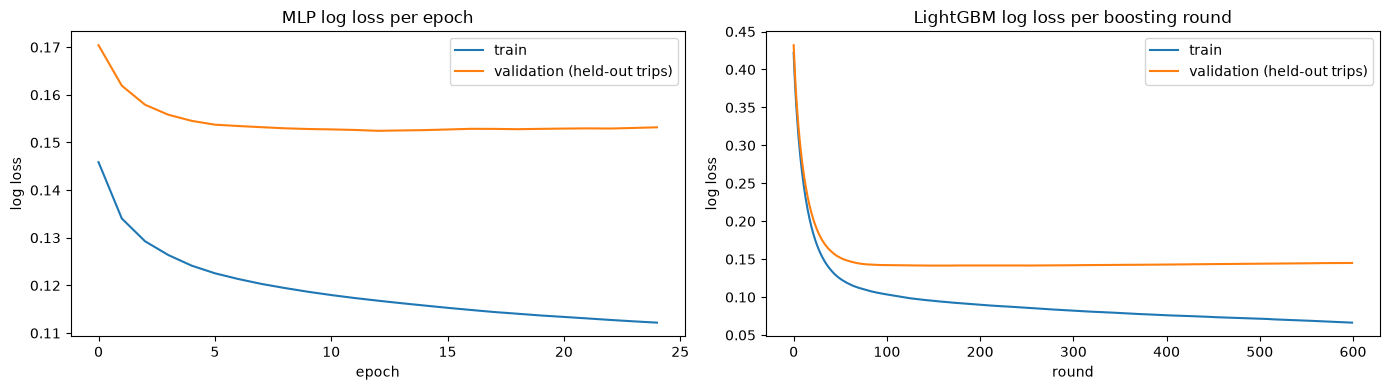

best LightGBM validation round: 164


In [8]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from lightgbm import LGBMClassifier
lab = ctr[ctr.label >= 0]
tr_i, va_i = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(lab, groups=lab.trip_id))
A, V = lab.iloc[tr_i].sample(300_000, random_state=SEED), lab.iloc[va_i]
sc = StandardScaler().fit(A[FEATURES]); Xa, Xv = sc.transform(A[FEATURES]), sc.transform(V[FEATURES])
mlp = MLPClassifier(hidden_layer_sizes=(64, 32), batch_size=1024, random_state=SEED)
hist = []
for ep in range(25):
    mlp.partial_fit(Xa, A.label, classes=[0, 1])
    hist.append((log_loss(A.label, mlp.predict_proba(Xa)[:, 1]), log_loss(V.label, mlp.predict_proba(Xv)[:, 1])))
lg = LGBMClassifier(n_estimators=600, learning_rate=0.05, num_leaves=63, random_state=SEED, verbose=-1)
lg.fit(A[FEATURES], A.label, eval_X=(A[FEATURES], V[FEATURES]), eval_y=(A.label, V.label), eval_names=["train", "valid"], eval_metric="binary_logloss")
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
h = np.array(hist); ax[0].plot(h[:, 0], label="train"); ax[0].plot(h[:, 1], label="validation (held-out trips)")
ax[0].set(title="MLP log loss per epoch", xlabel="epoch", ylabel="log loss"); ax[0].legend()
ax[1].plot(lg.evals_result_["train"]["binary_logloss"], label="train"); ax[1].plot(lg.evals_result_["valid"]["binary_logloss"], label="validation (held-out trips)")
ax[1].set(title="LightGBM log loss per boosting round", xlabel="round", ylabel="log loss"); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT / "plots/03_training_curves.png", dpi=130); plt.show()
print("best LightGBM validation round:", int(np.argmin(lg.evals_result_["valid"]["binary_logloss"])) + 1)

## 7. Selection

In [9]:
rank = table.drop(index="Baseline: nearest arc").sort_values(["cv_top1_acc", "cv_log_loss"], ascending=[False, True])
print(rank[["cv_top1_acc", "cv_std_top1_acc", "cv_log_loss", "test_top1_acc", "test_log_loss", "inference_ms_per_1k_points"]].round(4))
best = rank.index[0]
json.dump({"selected_model": best, "rule": "highest CV point-level Top-1 accuracy; tie-break lower CV log loss"}, open(OUT / "selection.json", "w"), indent=2)
print("selected:", best)

                    cv_top1_acc  cv_std_top1_acc  cv_log_loss  test_top1_acc  \
model                                                                          
LightGBM                 0.8615           0.0602       0.1183         0.8770   
RandomForest             0.8596           0.0597       0.1205         0.8705   
MLP                      0.8553           0.0599       0.1286         0.8632   
LogisticRegression       0.8457           0.0587       0.1745         0.8482   
KNN                      0.8387           0.0583       0.1910         0.8467   
GaussianNB               0.7704           0.0546       1.2551         0.7654   

                    test_log_loss  inference_ms_per_1k_points  
model                                                          
LightGBM                   0.1039                     14.9001  
RandomForest               0.1079                     10.0329  
MLP                        0.1168                      0.8975  
LogisticRegression         0.1631      